
TÜM VERİ DAĞILIMI
 label
0    15637
2     5734
1     3815
Name: count, dtype: int64

TRAIN
 label
0    10946
2     4014
1     2670
Name: count, dtype: int64

VAL
 label
0    1563
2     573
1     382
Name: count, dtype: int64

TEST
 label
0    3128
2    1147
1     763
Name: count, dtype: int64


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

... (7 outputs left out)

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:668: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:668: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)



📊 GENEL METRİK TABLOSU (BERT – English)


,Accuracy,Precision,Recall,F1-score
Train,0.954396,0.954206,0.954396,0.954228
Validation,0.939635,0.939125,0.939635,0.939275
Test,0.943628,0.943231,0.943628,0.943326


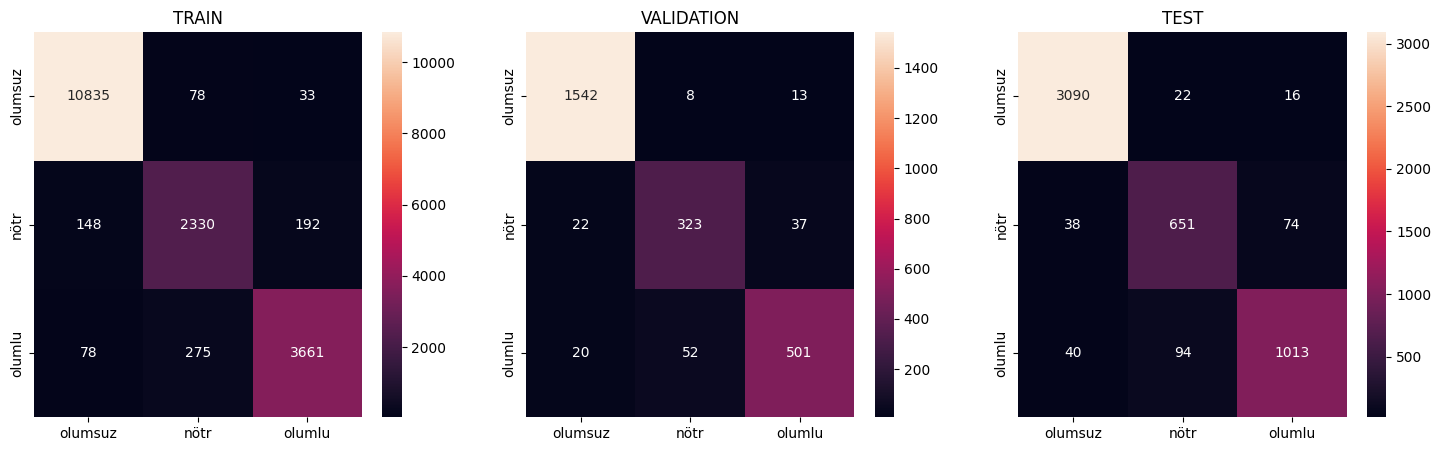

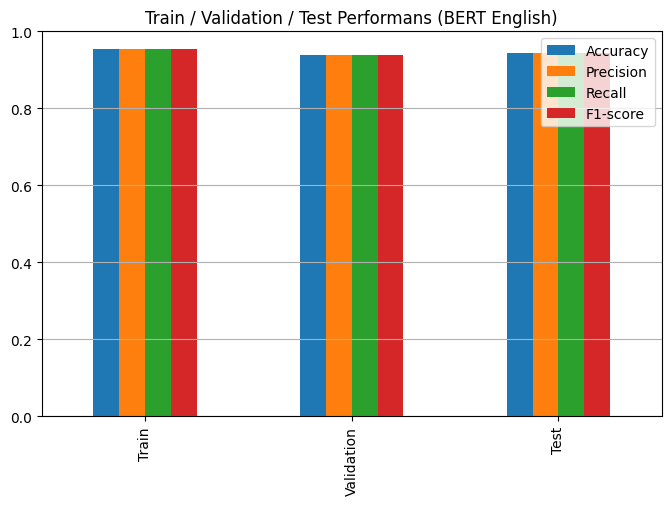

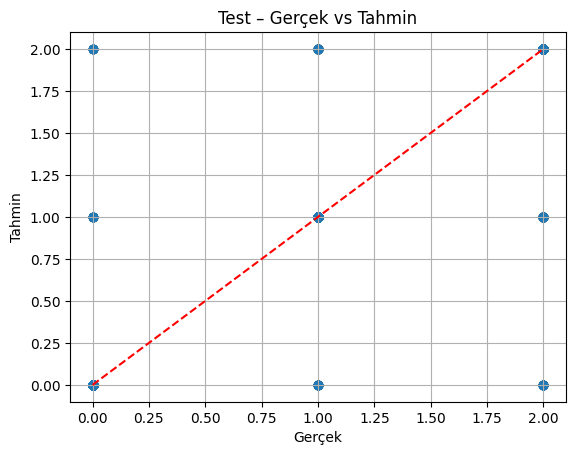

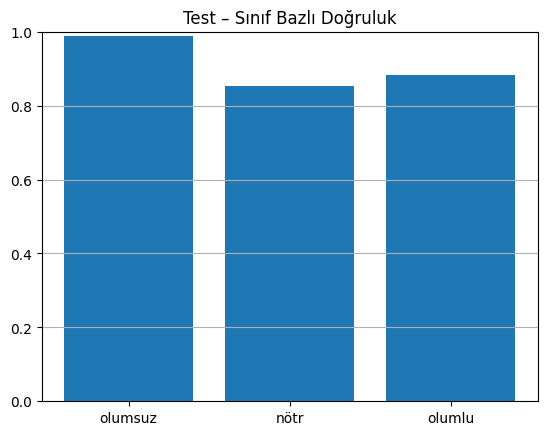

In [1]:
# =========================================================
# 0) KURULUM
# =========================================================
!pip install -q transformers datasets accelerate

# =========================================================
# 1) KÜTÜPHANELER
# =========================================================
import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix
)

from transformers import (
    BertForSequenceClassification,
    BertTokenizerFast,
    TrainingArguments,
    Trainer
)

from datasets import Dataset

# =========================================================
# 2) VERİ SETİNİ YÜKLE (TEK CSV)
# =========================================================
df = pd.read_csv("Turkish-Review-Sentiment-Data.csv")
df = df.rename(columns={"review": "text", "sentiment": "duygu"})
df = df[["text", "duygu"]].dropna()

# =========================================================
# 3) LABEL MAPPING
# =========================================================
label_map = {"olumsuz": 0, "nötr": 1, "olumlu": 2}

df["label"] = (
    df["duygu"]
    .astype(str)
    .str.lower()
    .str.replace(" ", "")
    .map(label_map)
)

df = df.dropna(subset=["label"])
df["label"] = df["label"].astype(int)

print("\nTÜM VERİ DAĞILIMI\n", df["label"].value_counts())

# =========================================================
# 4) %70 TRAIN – %20 TEST – %10 VAL
# =========================================================
train_df, temp_df = train_test_split(
    df, test_size=0.30, stratify=df["label"], random_state=42
)

val_df, test_df = train_test_split(
    temp_df, test_size=2/3, stratify=temp_df["label"], random_state=42
)

print("\nTRAIN\n", train_df["label"].value_counts())
print("\nVAL\n", val_df["label"].value_counts())
print("\nTEST\n", test_df["label"].value_counts())

# =========================================================
# 5) TOKENIZER (BERT – ENGLISH)
# =========================================================
MODEL_NAME = "bert-base-uncased"

tokenizer = BertTokenizerFast.from_pretrained(MODEL_NAME)

def tokenize(batch):
    return tokenizer(
        batch["text"],
        truncation=True,
        padding="max_length",
        max_length=48
    )

train_ds = Dataset.from_pandas(train_df).map(tokenize, batched=True)
val_ds   = Dataset.from_pandas(val_df).map(tokenize, batched=True)
test_ds  = Dataset.from_pandas(test_df).map(tokenize, batched=True)

for ds in [train_ds, val_ds, test_ds]:
    ds.set_format("torch", columns=["input_ids", "attention_mask", "label"])

train_ds = train_ds.rename_column("label", "labels")
val_ds   = val_ds.rename_column("label", "labels")
test_ds  = test_ds.rename_column("label", "labels")

# =========================================================
# 6) MODEL
# =========================================================
model = BertForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3
)

# =========================================================
# 7) METRICS
# =========================================================
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)
    return {
        "accuracy": accuracy_score(labels, preds),
        "precision": precision_score(labels, preds, average="macro"),
        "recall": recall_score(labels, preds, average="macro"),
        "f1": f1_score(labels, preds, average="macro"),
    }

# =========================================================
# 8) TRAINING ARGUMENTS
# =========================================================
args = TrainingArguments(
    output_dir="./bert_english",
    num_train_epochs=2,
    per_device_train_batch_size=64,
    per_device_eval_batch_size=64,
    learning_rate=2e-5,
    weight_decay=0.01,
    fp16=True,

    eval_strategy="steps",
    eval_steps=1000,
    save_steps=1000,

    logging_steps=200,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    report_to="none"
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    compute_metrics=compute_metrics
)

# =========================================================
# 9) EĞİTİM
# =========================================================
trainer.train()

# =========================================================
# 10) TAHMİNLER
# =========================================================
def predict(dataset):
    return np.argmax(trainer.predict(dataset).predictions, axis=1)

y_train_true = train_df["label"].values
y_val_true   = val_df["label"].values
y_test_true  = test_df["label"].values

y_train_pred = predict(train_ds)
y_val_pred   = predict(val_ds)
y_test_pred  = predict(test_ds)

# =========================================================
# 11) METRİK TABLOSU
# =========================================================
def metric_row(y_true, y_pred):
    return [
        accuracy_score(y_true, y_pred),
        precision_score(y_true, y_pred, average="weighted"),
        recall_score(y_true, y_pred, average="weighted"),
        f1_score(y_true, y_pred, average="weighted")
    ]

results = pd.DataFrame(
    [
        metric_row(y_train_true, y_train_pred),
        metric_row(y_val_true, y_val_pred),
        metric_row(y_test_true, y_test_pred)
    ],
    columns=["Accuracy", "Precision", "Recall", "F1-score"],
    index=["Train", "Validation", "Test"]
)

print("\n📊 GENEL METRİK TABLOSU (BERT – English)")
display(results)

# =========================================================
# 12) TÜM GRAFİKLER
# =========================================================

# Confusion Matrices
fig, ax = plt.subplots(1,3, figsize=(18,5))
for i, (y_t, y_p, title) in enumerate([
    (y_train_true, y_train_pred, "TRAIN"),
    (y_val_true, y_val_pred, "VALIDATION"),
    (y_test_true, y_test_pred, "TEST")
]):
    sns.heatmap(confusion_matrix(y_t, y_p), annot=True, fmt="d",
                xticklabels=["olumsuz","nötr","olumlu"],
                yticklabels=["olumsuz","nötr","olumlu"], ax=ax[i])
    ax[i].set_title(title)
plt.show()

# Performans karşılaştırma
results.plot(kind="bar", figsize=(8,5))
plt.ylim(0,1)
plt.title("Train / Validation / Test Performans (BERT English)")
plt.grid(axis="y")
plt.show()

# Gerçek vs Tahmin (Test)
plt.scatter(y_test_true, y_test_pred, alpha=0.4)
plt.plot([0,2],[0,2],"r--")
plt.xlabel("Gerçek")
plt.ylabel("Tahmin")
plt.title("Test – Gerçek vs Tahmin")
plt.grid()
plt.show()

# Sınıf Bazlı Doğruluk (Test)
cm = confusion_matrix(y_test_true, y_test_pred)
class_acc = cm.diagonal() / cm.sum(axis=1)
plt.bar(["olumsuz","nötr","olumlu"], class_acc)
plt.ylim(0,1)
plt.title("Test – Sınıf Bazlı Doğruluk")
plt.grid(axis="y")
plt.show()


In [4]:
# =========================================================
# 13) DIŞ TEST SETİ (XLSX) – BERT (ENGLISH)
# =========================================================

# === 1) XLSX DOSYASINI OKU ===
xlsx_path = "ml proje.xlsx"
ext_df = pd.read_excel(xlsx_path)

# === 2) METİN SÜTUNUNU BUL ===
ext_df.columns = ext_df.columns.str.lower().str.strip()

if "yorum" in ext_df.columns:
    text_col = "yorum"
elif "review" in ext_df.columns:
    text_col = "review"
elif "text" in ext_df.columns:
    text_col = "text"
else:
    raise ValueError("❌ XLSX dosyasında yorum sütunu bulunamadı")

# === 3) SADECE METİN SÜTUNU İLE DATASET OLUŞTUR ===
text_df = ext_df[[text_col]].rename(columns={text_col: "text"})
text_df = text_df.dropna().reset_index(drop=True)

print(f"\n📂 XLSX Test Örnek Sayısı: {len(text_df)}")

# === 4) DATASET + TOKENIZATION (BERT) ===
ext_ds = Dataset.from_pandas(text_df)

ext_ds = ext_ds.map(
    lambda x: tokenizer(
        x["text"],
        truncation=True,
        padding="max_length",
        max_length=48
    ),
    batched=True
)

ext_ds.set_format(
    "torch",
    columns=["input_ids", "attention_mask"]
)

# === 5) MODEL TAHMİNİ ===
pred_output = trainer.predict(ext_ds)

logits = pred_output.predictions
probs = torch.softmax(torch.tensor(logits), dim=1).numpy()
pred_labels = np.argmax(probs, axis=1)

# === 6) LABEL → METİN ===
inv_label_map = {0: "olumsuz", 1: "nötr", 2: "olumlu"}

# === 7) SONUÇLARI ORİJİNAL DF’E EKLE ===
ext_df = ext_df.loc[text_df.index].reset_index(drop=True)

ext_df["tahmin_label"] = pred_labels
ext_df["tahmin_duygu"] = [inv_label_map[i] for i in pred_labels]

ext_df["prob_olumsuz"] = probs[:, 0]
ext_df["prob_notr"]    = probs[:, 1]
ext_df["prob_olumlu"]  = probs[:, 2]

# === 8) XLSX OLARAK KAYDET ===
output_path = "bert_english_xlsx_tahmin_sonuclari.xlsx"
ext_df.to_excel(output_path, index=False)

print(f"\n✅ BERT (English) tahminleri kaydedildi: {output_path}")

# === 9) ÖRNEK GÖSTER ===
display(ext_df.head(10))



📂 XLSX Test Örnek Sayısı: 500


Map:   0%|          | 0/500 [00:00<?, ? examples/s]

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:668: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)



✅ BERT (English) tahminleri kaydedildi: bert_english_xlsx_tahmin_sonuclari.xlsx


,marka,ürün,yorum,beden,cinsiyet,tarih,yıldız,duygu,tahmin_label,tahmin_duygu,prob_olumsuz,prob_notr,prob_olumlu
0,mavi,Jake Pro Sport Gece Mavisi Jean Pantolon 00422...,Ürün güzel fakat yaz aylarında giyilmez çok ka...,32/30,erkek,2025-07-21,2,olumsuz,0,olumsuz,0.974457,0.021166,0.004377
1,mavi,Jake Pro Sport Gece Mavisi Jean Pantolon 00422...,İkinci defa Siyah istedim yine lacivert geldi ...,34/32,erkek,2025-07-16,5,olumlu,0,olumsuz,0.994419,0.003746,0.001835
2,mavi,Jake Pro Sport Gece Mavisi Jean Pantolon 00422...,Bayıldım harika,33/32,erkek,2025-08-19,5,olumlu,1,nötr,0.039807,0.883351,0.076842
3,mavi,Star Gold Shape Puslu Buz Jean Pantolon 101077...,çok güzelmiş çok beğendim teşekkürler,27/27,kadın,2025-11-12,5,olumlu,2,olumlu,0.281738,0.162272,0.555990
4,mavi,Star Gold Shape Puslu Buz Jean Pantolon 101077...,rengi daha açık bir beden küçük alınabilir,33/27,kadın,2025-11-10,4,olumlu,0,olumsuz,0.986953,0.009890,0.003157
5,mavi,Star Gold Shape Puslu Buz Jean Pantolon 101077...,155 49 kiloyaa 25 25 beden tam oldu rengi çok ...,25/25,kadın,2025-06-16,5,olumlu,0,olumsuz,0.941876,0.047387,0.010738
6,mavi,Star Gold Shape Puslu Buz Jean Pantolon 101077...,Ürünün fotoğrafla alakası yok 52-53-54 kiloya ...,26/25,kadın,2025-11-10,1,olumsuz,0,olumsuz,0.994524,0.003743,0.001733
7,mavi,Marcus Antrasit Smoke Jean Pantolon 8835126868,ürün güzel tavsiye ederim,36/30,erkek,2025-11-12,4,olumlu,1,nötr,0.060077,0.868976,0.070947
8,mavi,Marcus Antrasit Smoke Jean Pantolon 8835126868,Süper tam kalıp rengi dumanlı gri,34/30,erkek,2025-11-09,5,olumlu,0,olumsuz,0.705850,0.138233,0.155917
9,mavi,Marcus Antrasit Smoke Jean Pantolon 8835126868,Defalarca yıkanmış solmuş gibi duruyor. Rengin...,33/32,erkek,2025-11-04,2,olumsuz,0,olumsuz,0.994803,0.003060,0.002137



===== BERT (ENGLISH) – DIŞ TEST XLSX METRİKLER =====
Accuracy : 0.294
Precision: 0.654916129032258
Recall   : 0.294
F1-score : 0.3134188745878685

DETAYLI SINIF RAPORU

              precision    recall  f1-score   support

     olumsuz       0.20      0.67      0.31        76
        nötr       0.13      0.31      0.18        64
      olumlu       0.84      0.21      0.34       360

    accuracy                           0.29       500
   macro avg       0.39      0.40      0.28       500
weighted avg       0.65      0.29      0.31       500



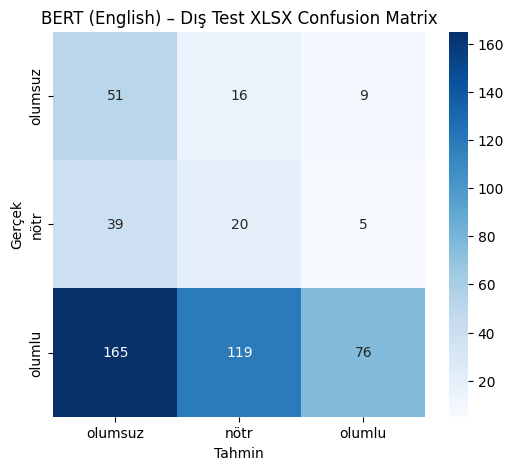

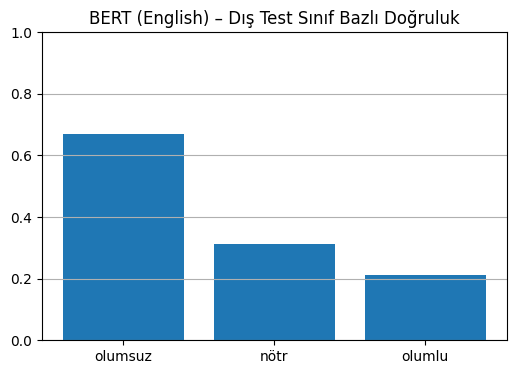

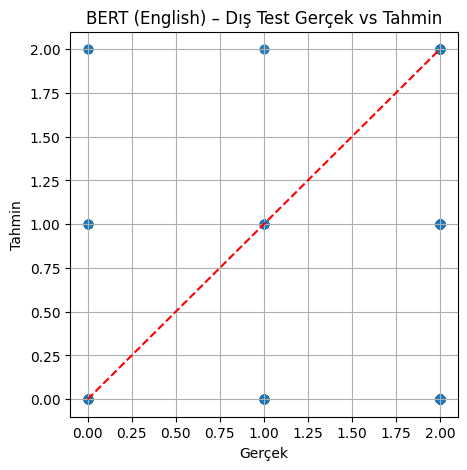


📁 XLSX çıktısı oluşturuldu → bert_english_dis_test_sonuclari.xlsx


In [5]:
# =========================================================
# 14) (VARSA) GERÇEK ETİKETLERİ BUL
# =========================================================
label_col = None
ext_df.columns = ext_df.columns.str.lower().str.strip()

if "duygu" in ext_df.columns:
    label_col = "duygu"
elif "sentiment" in ext_df.columns:
    label_col = "sentiment"

if label_col:
    ext_df[label_col] = (
        ext_df[label_col]
        .astype(str)
        .str.lower()
        .str.replace(" ", "")
    )
    ext_df["gercek_label"] = ext_df[label_col].map(label_map)
else:
    print("\n⚠️ XLSX içinde gerçek etiket bulunamadı → metrik hesaplanmayacak")

# =========================================================
# 15) METRİKLER (EĞER GERÇEK ETİKET VARSA)
# =========================================================
if label_col and ext_df["gercek_label"].notna().any():

    y_true = ext_df["gercek_label"].values
    y_pred = ext_df["tahmin_label"].values

    print("\n===== BERT (ENGLISH) – DIŞ TEST XLSX METRİKLER =====")
    print("Accuracy :", accuracy_score(y_true, y_pred))
    print("Precision:", precision_score(y_true, y_pred, average="weighted"))
    print("Recall   :", recall_score(y_true, y_pred, average="weighted"))
    print("F1-score :", f1_score(y_true, y_pred, average="weighted"))

    print("\nDETAYLI SINIF RAPORU\n")
    print(classification_report(
        y_true,
        y_pred,
        target_names=["olumsuz", "nötr", "olumlu"]
    ))

    # =====================================================
    # 16) CONFUSION MATRIX (ÇOK ÖNEMLİ)
    # =====================================================
    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(6,5))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["olumsuz","nötr","olumlu"],
        yticklabels=["olumsuz","nötr","olumlu"]
    )
    plt.xlabel("Tahmin")
    plt.ylabel("Gerçek")
    plt.title("BERT (English) – Dış Test XLSX Confusion Matrix")
    plt.show()

    # =====================================================
    # 17) SINIF BAZLI DOĞRULUK
    # =====================================================
    class_acc = cm.diagonal() / cm.sum(axis=1)

    plt.figure(figsize=(6,4))
    plt.bar(["olumsuz","nötr","olumlu"], class_acc)
    plt.ylim(0,1)
    plt.title("BERT (English) – Dış Test Sınıf Bazlı Doğruluk")
    plt.grid(axis="y")
    plt.show()

    # =====================================================
    # 18) GERÇEK vs TAHMİN
    # =====================================================
    plt.figure(figsize=(5,5))
    plt.scatter(y_true, y_pred, alpha=0.4)
    plt.plot([0,2],[0,2],"r--")
    plt.xlabel("Gerçek")
    plt.ylabel("Tahmin")
    plt.title("BERT (English) – Dış Test Gerçek vs Tahmin")
    plt.grid()
    plt.show()

# =========================================================
# 19) XLSX ÇIKTI (HER DURUMDA)
# =========================================================
final_output_path = "bert_english_dis_test_sonuclari.xlsx"
ext_df.to_excel(final_output_path, index=False)

print(f"\n📁 XLSX çıktısı oluşturuldu → {final_output_path}")
